# Midterm Examination

# Part#1 Pandas data operation (10pts) 

### Answer the below the problems for pandas data preparation

In [1]:
import numpy as np
import pandas as pd

### Problem#1 Create a Python program that converts the given data dictionary into a Pandas DataFrame named df.

Expected Output:
    Name  Math  Science  English
0     John    85       80       90
1    James    72       75       68
2  Heleina    90       88       92
3      Sam    65       70       75

In [2]:
data = {
    "Name": ["John", "James", "Helena", "Sam"],
    "Math": [85, 72, 90, 65],
    "Science": [80, 75, 88, 70],
    "English": [90, 68, 92, 75]
}

df = pd.DataFrame(data)
print(df)

     Name  Math  Science  English
0    John    85       80       90
1   James    72       75       68
2  Helena    90       88       92
3     Sam    65       70       75


###  Problem#2  Create a Python program that calculates the total grades of each student by adding their Math, Science, and English grades. Store the result in a new column named Total.


Expected Output:

      Name  Math  Science  English  Total
0     John    85       80       90    255
1    James    72       75       68    215
2  Heleina    90       88       92    270
3      Sam    65       70       75    210

In [3]:
df["Total"] = df["Math"] + df["Science"] + df["English"]
print(df)

     Name  Math  Science  English  Total
0    John    85       80       90    255
1   James    72       75       68    215
2  Helena    90       88       92    270
3     Sam    65       70       75    210


### Problem #3: Compute the Average Grades per Student
Create a Python program that calculates the average grade of each student using their Math, Science, and English grades. Store the result in a new column named Average. (Decimal point must be 2 digits)

Expected Output:
      Name  Math  Science  English  Average
0     John    85       80       90    85.00
1    James    72       75       68    71.67
2  Heleina    90       88       92    90.00
3      Sam    65       70       75    70.00

In [4]:
df["Average"] = df[["Math", "Science", "English"]].mean(axis=1).round(2)
print(df)

     Name  Math  Science  English  Total  Average
0    John    85       80       90    255    85.00
1   James    72       75       68    215    71.67
2  Helena    90       88       92    270    90.00
3     Sam    65       70       75    210    70.00


### Problem #4: Convert Average Grades into Letter Grades

Create a Python program that calculates the average grade of each student based on their Math, Science, and English grades. Convert each student's average grade into a letter grade using the following grading scale:

A – Average grade of 80 and above

B – Average grade of 70 to 79

C – Average grade below 70

Store the letter grade in a new column named Grade.

Expected Output:

      Name  Math  Science  English  Average Grade
0     John    85       80       90    85.00    A
1    James    72       75       68    71.67    B
2  Heleina    90       88       92    90.00    A
3      Sam    65       70       75    70.00    B

In [57]:
def get_grade(average):
    if average >= 80:
        return "A"
    elif average >= 70:
        return "B"
    else:
        return "C"

df["Grade"] = df["Average"].apply(get_grade)
print(df)

     Name  Math  Science  English  Total  Average Grade
0    John    85       80       90    255    85.00     A
1   James    72       75       68    215    71.67     B
2  Helena    90       88       92    270    90.00     A
3     Sam    65       70       75    210    70.00     B


### Problem #5: Calculate the Total Grades per Subject

Create a Python program that calculates the sum of all students' grades in Math, Science, and English. Display the results for each subject.

### Problem #6: Find the Highest Grade in Each Subject

Create a Python program that determines the highest grade obtained by any student in Math, Science, and English.

### Problem #7: Display the Student with the Highest Total Grade

Create a Python program that computes each student's total grade and displays the name and total grade of the student with the highest total.

### Problem #8: Create a Bar Chart of Student Grades

Create a Python program using Pandas and Matplotlib to display the Math, Science, and English grades of each student using a bar chart.

Requirements:

-Use the Name column for the x-axis.

-Display the Math, Science, and English grades for each student.

-Add a chart title: Student Grades per Subject.

-Label the x-axis as Students.

-Label the y-axis as Grades.

-Add a legend to identify each subject.

-Display the chart using plt.show().

In [5]:
import matplotlib.pyplot as plt

In [23]:
subjects_list = df.columns[1:4].tolist()
print(subjects_list)


['Math', 'Science', 'English']


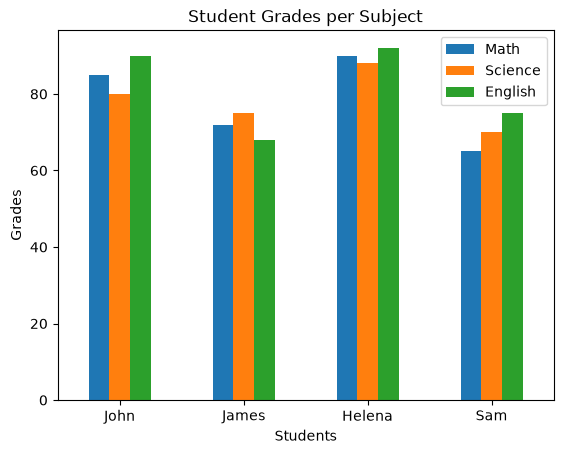

In [31]:
# Assigned this chart to bar_plot to isolate the edits within the chart itslef
bar_plot = df.plot(
    x="Name",
    y=subjects_list,
    kind="bar"
)

bar_plot.set_title("Student Grades per Subject")
bar_plot.set_xlabel("Students")
bar_plot.tick_params(axis="x", rotation=0) # This is so we can rotate the names horizontally
bar_plot.set_ylabel("Grades")
bar_plot.legend()
plt.show()

### Problem #9: Create a Line Graph of Student Grades

Create a Python program using Pandas and Matplotlib to compare the grades of students in Math, Science, and English using a line graph.

Requirements:

-Use student names on the x-axis.

-Plot a separate line for Math, Science, and English.

-Add a chart title: Comparison of Student Grades.

-Label the x-axis as Students.

-Label the y-axis as Grades.

-Add a legend to identify each subject.

-Display markers for each student's grade.

-Display the chart using plt.show().

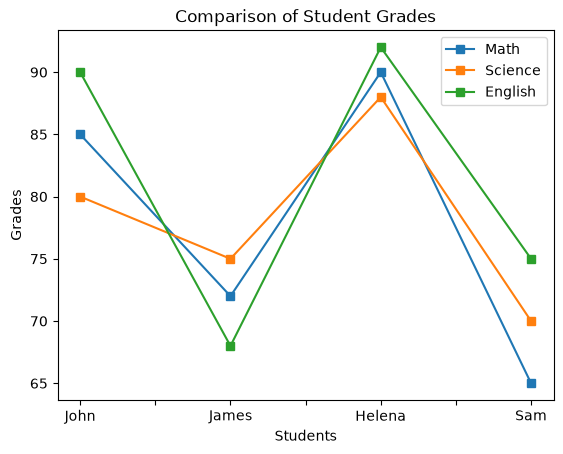

In [40]:
line_plot = df.plot(
    x="Name",
    y=subjects_list,
    kind="line",
    marker="s" #According to Matplotlib documentation, marker "s" signifies square
)

line_plot.set_title("Comparison of Student Grades")
line_plot.set_xlabel("Students")
line_plot.set_ylabel("Grades")
line_plot.legend()
line_plot.tick_params(axis="x", rotation=0)
plt.show()

### Problem #10: Create Multiple Graphs Using Subplots

Create a Python program using Pandas and Matplotlib to display three different graphs in a single figure using subplots.

Requirements:

Create a figure containing three subplots arranged in 1 row and 3 columns.

The first subplot must display a bar chart of Math grades.

The second subplot must display a bar chart of Science grades.

The third subplot must display a bar chart of English grades.

Each subplot must have its own title.

Label the x-axis as Students and the y-axis as Grades for each subplot.

Add a legend to each subplot.

Add an overall figure title: Student Grade Analysis Dashboard.

Adjust the layout to prevent overlapping titles and labels.

Display all graphs using plt.show().

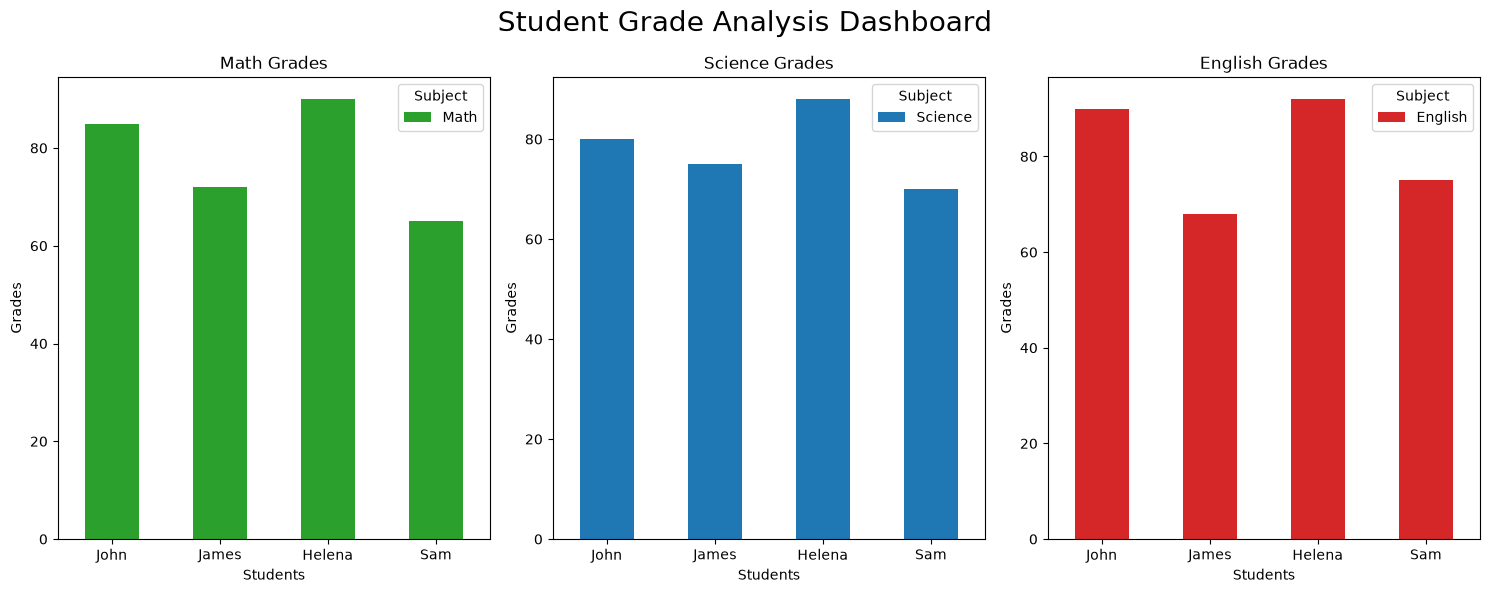

In [78]:
fig, (math_subplot, science_subplot, english_subplot) = plt.subplots(
    ncols=3, nrows=1, figsize=(15, 6)
)
fig.suptitle("Student Grade Analysis Dashboard", fontsize=20)

# Configures the Math grade subplot
math_bar = df.plot(
    ax=math_subplot,
    x="Name",
    y="Math",
    color="tab:green",
    kind="bar",
    legend=True,
)
math_subplot.set_title("Math Grades")
math_subplot.set_xlabel("Students")
math_subplot.set_ylabel("Grades")
math_subplot.legend(title="Subject")

# Configures the Science grade subplot
science_bar = df.plot(
    ax=science_subplot,
    x="Name",
    y="Science",
    kind="bar",
    legend=True,
)
science_subplot.set_title("Science Grades")
science_subplot.set_xlabel("Students")
science_subplot.set_ylabel("Grades")
science_subplot.legend(title="Subject")

# Configures the English grade subplot
english_bar = df.plot(
    ax=english_subplot,
    x="Name",
    y="English",
    color="tab:red",
    kind="bar",
    legend=True,
)
english_subplot.set_title("English Grades")
english_subplot.set_xlabel("Students")
english_subplot.set_ylabel("Grades")
english_subplot.legend(title="Subject")

for subplot in (math_subplot, science_subplot, english_subplot):
    subplot.tick_params(axis="x", rotation=0)

fig.tight_layout(rect=(0, 0, 1, 1))
plt.show()


# Part 2 Cleaning Data using Pandas (20pts)

### Identifying and Cleaning Data Quality Issues in the Titanic Dataset

Objective: Develop a Python program using Pandas to identify, analyze, and handle common data quality issues in the Titanic dataset.

dataset file: [Titanic Dataset](https://drive.google.com/file/d/13sf9EXV-bDA_28bQ9f7roZD2_jzVM819/view?usp=sharing)

Task: 

-Download the dataset file

-Load the dataset into a Pandas DataFrame named df.

-Your task is to inspect the dataset and identify the data issues.

-After identifying the problems, clean the dataset and display a summary of the data quality issues before and after cleaning.

-document your work (Summary of the cleaning operations performed)